# Contextual Alertness — Midterm Project
**FINM 36700 · Portfolio and Risk Management · Autumn 2026**

**Group:** HW Group B — Avi Rastogi, Lucas Albin Lazcano, Mengting Wang, Siena Verprauskus

**Use of AI:** Generative AI (Claude) was used for notebook scaffolding, code drafting and debugging, and review of interpretation in Sections _X–Y_. All results and judgments were checked by the group.

## Project Statement

At the December 31, 2024 close a fictional long-short equity fund, Contextual Alertness, holds six memory, optical-networking and data-center names against six application-software names: 400% gross, 0% net, equal weights within each sleeve. The book is a stylized stand-in inspired by a real fund's publicly reported positioning. It is not that fund's holdings. Over the next eighteen months the book rises many-fold, then loses most of that gain in four sessions, July 24 to 29, 2026.

You are the risk manager. Take the book as given. Measure its risk, locate where the risk sat, say what a one-day VaR could and could not have told you, and build the version of the same strategy you would have been willing to run.

## Context

| Long, +1/3 of NAV each | Theme | Short, -1/3 of NAV each | Theme |
|---|---|---|---|
| `SNDK` | memory and storage | `ADBE` | application software |
| `MU` | memory | `CRM` | application software |
| `VRT` | data-center power and cooling | `ORCL` | enterprise software |
| `LITE` | optical networking | `NOW` | enterprise software |
| `COHR` | optical networking | `WDAY` | application software |
| `BE` | data-center power | `MDB` | database software |

The long sleeve is +200% of NAV and the short sleeve -200%, so gross exposure is 400% and net exposure is zero. The `SNDK` column is one strategy slot: it carries `WDC` returns through February 21, 2025 and `SNDK` returns from February 24, 2025, when Sandisk began regular-way trading; the switch is already in the supplied series.

The fund runs a mandate. At every close the book is reset to the target weights, so gross stays at 4x and net at zero: the **4x book**. Dividing every weight by four gives the **1x book**, the same positions at 100% gross.

Everything through July 31, 2026 is yours to study. The holdout, August 3 to October 26, 2026, exists for one purpose: Section 6 has you declare criteria, build controls on the design window, then run them, unchanged, on the holdout. Do not tune anything to it. If you study it earlier, the test in 6.3 stops measuring anything.

## Data

| File | Sheets | Frequency | Sample |
|---|---|---|---|
| `data/project_situational_awareness_20261026.xlsx` | `descriptions`, `total return indexes`, `total returns`, `baseline weights`, `data source`, `checks` | daily | 2020-12-31 to 2026-10-26 |

The `total returns` sheet holds the twelve names, `SPY`, `QQQ`, `SMH`, the eleven sector ETFs (`XLK XLI XLF XLC XLRE XLE XLY XLB XLV XLU XLP`) and `SHV`, as gross-dividend total returns. `descriptions` gives each ticker's name, theme and side; `baseline weights` gives the twelve target weights.

### Notes

- Returns are daily, close to close, simple total returns. A weight set at the close of $t$ earns the return of $t+1$: $r^{\text{book}}_{t+1} = \boldsymbol{w}_t' \boldsymbol{r}_{t+1}$. Annualize with 252 trading days.
- The daily reset is a strategy-index convention: resetting to the target weights at every close makes 4x the book's exposure on every day, so Sections 3 to 5 measure the risk of a fixed-leverage book. Section 2 shows what the convention assumes away.
- Cash is `SHV`. Names and factors enter every regression in excess of `SHV`. The book's weights sum to zero, so its return $\boldsymbol{w}'\boldsymbol{r}$ is already an excess return and its Sharpe ratio uses it directly; the fund's NAV earns `SHV` on top of it.
- VaR and CVaR are positive loss magnitudes, one-day at the 5% level unless a question says otherwise. A forecast for day $t$ uses data through $t-1$. A breach is a day whose realized loss exceeds the VaR forecast made for it. EWMA uses $\lambda = 0.94$ and a zero mean; you choose how to initialize $\sigma^2$ and state it.
- The **design window** ends July 31, 2026. The **report window** is January 2, 2025 to July 31, 2026. The **holdout** runs from August 3, 2026 to October 26, 2026, the end of the file. Use the design window for all estimation and design. Open the holdout once, in 6.3, to evaluate the controls and criteria already specified. The final recommendation in 7.4 may use that verdict; do not re-tune the controls on the holdout.
- The **four-day loss** is the compounded loss of the daily-reset 4x book over July 24 to 29, 2026, $1 - \prod_{t=1}^{4}(1 + r_t)$, with $r_t$ the book's daily return.
- Ignore financing, stock-borrow fees, transaction costs, taxes and market impact.

## Setup

In [29]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

DATA = Path('../data') / 'project_situational_awareness_20261026.xlsx'

weights     = pd.read_excel(DATA, sheet_name='baseline weights').set_index('ticker')['equal-sleeve weight']
descriptions = pd.read_excel(DATA, sheet_name='descriptions').set_index('ticker')
returns_all = pd.read_excel(DATA, sheet_name='total returns', index_col='Date', parse_dates=True)

DESIGN_END = pd.Timestamp('2026-07-31')
returns = returns_all.loc[:DESIGN_END]                              #most questions use returns up to 31st of july, except 6.1

# Windows
FULL     = slice('2021-01-04', '2026-06-30')
RECENT   = slice('2025-01-02', '2026-06-30')
REPORT   = slice('2025-01-02', '2026-07-31')
REVERSAL = slice('2026-07-24', '2026-07-29')

# Tickers
tickers       = weights.index.tolist()
long_tickers  = weights[weights > 0].index.tolist()
short_tickers = weights[weights < 0].index.tolist()

# Books (daily reset): already excess returns since weights sum to zero
book_4x = returns[tickers] @ weights
book_1x = book_4x / 4
rf = returns['SHV']

In [30]:
descriptions

,name,theme,side
ticker,,,
SNDK,Sandisk,memory and storage,long
MU,Micron Technology,memory,long
VRT,Vertiv,data-center power and cooling,long
LITE,Lumentum,optical networking,long
COHR,Coherent,optical networking,long
BE,Bloom Energy,data-center power,long
ADBE,Adobe,application software,short
CRM,Salesforce,application software,short
ORCL,Oracle,enterprise software,short


In [31]:
returns.describe().T

,count,mean,std,min,25%,50%,75%,max
SNDK,1400.0,0.003257,0.040940,-0.213016,-0.016529,0.000748,0.018967,0.275649
MU,1400.0,0.002326,0.034687,-0.161788,-0.016089,0.001007,0.019716,0.192916
VRT,1400.0,0.002582,0.038244,-0.367399,-0.016441,0.002631,0.022803,0.292498
LITE,1400.0,0.002170,0.038032,-0.224569,-0.015780,0.001249,0.019684,0.235666
COHR,1400.0,0.001657,0.039108,-0.298660,-0.017891,0.001166,0.022179,0.228531
BE,1400.0,0.002877,0.055240,-0.247903,-0.029408,0.000000,0.031284,0.591867
ADBE,1400.0,-0.000228,0.022894,-0.167932,-0.010812,0.000164,0.012015,0.145115
CRM,1400.0,0.000145,0.023107,-0.197371,-0.011429,0.000264,0.012010,0.114969
ORCL,1400.0,0.000887,0.026163,-0.137908,-0.010157,0.000868,0.011370,0.359488
NOW,1400.0,0.000388,0.027564,-0.177452,-0.013072,0.001536,0.014373,0.154854


In [32]:
weights

ticker
SNDK    0.333333
MU      0.333333
VRT     0.333333
LITE    0.333333
COHR    0.333333
BE      0.333333
ADBE   -0.333333
CRM    -0.333333
ORCL   -0.333333
NOW    -0.333333
WDAY   -0.333333
MDB    -0.333333
Name: equal-sleeve weight, dtype: float64

---
# 1. The Book as Given

## 1.1

> Verify the long, short, gross and net exposures as multiples of NAV and as dollars on $100 million of NAV. Then, for the 4x book and the 1x book, report over 2021-01-04 to 2026-06-30 and over 2025-01-02 to 2026-06-30:
> 
> - annualized mean and volatility, Sharpe ratio, skewness, excess kurtosis
> - worst day, empirical 5% VaR and CVaR
> - maximum drawdown with its peak and trough dates, and cumulative return
> 
> Group the statistics by how they respond to leverage. Explain the scaling and compounding within each group.

In [33]:
longs = weights[long_tickers]
shorts = weights[short_tickers]

long_exposure = longs.sum()
short_exposure = shorts.sum()

gross_exposure = long_exposure + abs(short_exposure)
net_exposure = long_exposure + short_exposure

NAV = 100

exposures = pd.DataFrame({
    'x NAV': [long_exposure, short_exposure, gross_exposure, net_exposure]
}, index=['Long', 'Short', 'Gross', 'Net'])

exposures['$M on $100M'] = exposures['x NAV'] * NAV
exposures.style.format({'x NAV': '{:.1f}', '$M on $100M': '{:,.0f}'})

,x NAV,$M on $100M
Long,2.0,200
Short,-2.0,-200
Gross,4.0,400
Net,0.0,0


_Answer:_ Exposures check out: long +2.0x ($200M), short −2.0x (−$200M), gross 4.0x ($400M), net 0.0x ($0) on $100M of NAV.

In [34]:
def path_stats(r):
    wealth = (1 + r).cumprod()
    dd = wealth / wealth.cummax() - 1
    trough = dd.idxmin()
    peak = wealth.loc[:trough].idxmax()

    return dd.min(), peak.date(), trough.date(), wealth.iloc[-1] - 1


def stats(r):
    ann_mean = r.mean() * 252
    ann_vol = r.std() * np.sqrt(252)
    sharpe = ann_mean / ann_vol
    skewness = r.skew()
    excess_kurt = r.kurt()
    
    worst_day = min(r)
    emp_VaR = -r.quantile(0.05)
    emp_CVaR = -r[r <= -emp_VaR].mean()
    
    max_drawdown, peak_date, trough_date, cum_return = path_stats(r)

    return pd.Series({
        'Ann. mean': ann_mean,
        'Ann. vol': ann_vol,
        'Sharpe': sharpe,
        'Skewness': skewness,
        'Excess Kurtosis': excess_kurt,
        "Worst Day": worst_day,
        "VaR": emp_VaR,
        "CVaR": emp_CVaR,
        "Max Drawdown": max_drawdown,
        "Peak": peak_date,
        "Trough": trough_date,
        "Cumulative Return": cum_return
    })

summary_stats = pd.DataFrame({"4x, 2021–2026": stats(book_4x[FULL]),
                            "4x, 2025–2026": stats(book_4x[RECENT]),
                            "1x, 2021–2026": stats(book_1x[FULL]),
                            "1x, 2025–2026": stats(book_1x[RECENT])})

pct_stats = ['Ann. mean', 'Ann. vol', 'Worst Day', 'VaR', 'CVaR', 'Max Drawdown', 'Cumulative Return']
ratio_stats = ['Sharpe', 'Skewness', 'Excess Kurtosis']

summary_stats.style.format('{:.2%}', subset=(pct_stats, summary_stats.columns)) \
                   .format('{:.2f}', subset=(ratio_stats, summary_stats.columns))

,"4x, 2021–2026","4x, 2025–2026","1x, 2021–2026","1x, 2025–2026"
Ann. mean,124.72%,424.81%,31.18%,106.20%
Ann. vol,89.87%,136.64%,22.47%,34.16%
Sharpe,1.39,3.11,1.39,3.11
Skewness,0.07,-0.34,0.07,-0.34
Excess Kurtosis,4.64,1.80,4.64,1.80
Worst Day,-35.96%,-35.96%,-8.99%,-8.99%
VaR,7.32%,13.63%,1.83%,3.41%
CVaR,12.35%,19.75%,3.09%,4.94%
Max Drawdown,-79.38%,-48.44%,-26.26%,-13.57%
Peak,2021-01-19,2026-05-13,2021-01-19,2026-05-13


In [35]:
num = summary_stats.drop(['Peak', 'Trough']).astype(float)
ratio = num['4x, 2021–2026'] / num['1x, 2021–2026']

print('Scales x4: ', list(ratio[np.isclose(ratio, 4)].index))
print('Invariant: ', list(ratio[np.isclose(ratio, 1)].index))
print('Non-linear:', list(ratio[~np.isclose(ratio, 4) & ~np.isclose(ratio, 1)].index))

Scales x4:  ['Ann. mean', 'Ann. vol', 'Worst Day', 'VaR', 'CVaR']
Invariant:  ['Sharpe', 'Skewness', 'Excess Kurtosis']
Non-linear: ['Max Drawdown', 'Cumulative Return']


**Answer 1.1.**

The descriptive statisticss respond to leverage in three different ways: they either scale by 4x, are invariant, or respond non-linearly. 

Annual mean, annual volatility, worst day, and empirical VaR and CVaR all scale linearly with leverage. This is expected, as they all depend on the size of each day's return, and all daily returns are scaled by 4x with leverage.

Sharpe, skewness and excess kurtosis remain equal across leverage levels. Sharpe remains the same because leverage amplifies returns but equally amplifies volatility. Skewness and excess kurtosis are characteristics of the daily return distribution which are unaffected by scaling, since they are standardized moments.

Finally, and most interestingly, maximum drawdown and cumulative returns are non-linear in leverage. Maximum drawdown goes from −26.3% to −79.4% (ratio 3.02) over 2021–2026. The reason it can't scale linearly because it is bounded by −100%, as the NAV cannot fall below 0, and because it is measured on the compounded path. Cumulative returns do not scale linearly because they are path-dependent and compound. Over 2021–2026 the 4x book returned 9,805% vs. 379% for the 1x book (ratio 25.9), and over 2025–2026 12,690% vs. 340% (ratio 37.3). 

## 1.2

> Report the compounded calendar-year return of the 4x book for 2021 through 2026 (to July 31), with the contribution of each sleeve, defined as the sum of the sleeve's daily weighted returns. The sleeve contributions add to the sum of the book's daily returns rather than to its compounded year; report both. In which years did the short sleeve add to the return, and in which did it subtract?

In [36]:
def sleeve_returns_yearly(r):
    book  = r[tickers] @ weights
    long  = r[long_tickers] @ weights[long_tickers]
    short = r[short_tickers] @ weights[short_tickers]

    return pd.Series({
        "Compounded book return": (1 + book).prod() - 1,
        "Sum of daily book returns": book.sum(),
        "Long sleeve contribution": long.sum(),
        "Short sleeve contribution": short.sum(),
    })

decomposed_returns = pd.DataFrame({"2021": sleeve_returns_yearly(returns.loc['2021']),
"2022": sleeve_returns_yearly(returns.loc['2022']),
"2023": sleeve_returns_yearly(returns.loc['2023']),
"2024": sleeve_returns_yearly(returns.loc['2024']),
"2025": sleeve_returns_yearly(returns.loc['2025']),
"2026": sleeve_returns_yearly(returns.loc['2026'])})

decomposed_returns.T.style.format('{:.1%}')

,Compounded book return,Sum of daily book returns,Long sleeve contribution,Short sleeve contribution
2021,-28.9%,-19.4%,36.6%,-55.9%
2022,-20.7%,-3.8%,-79.1%,75.3%
2023,-34.8%,-25.1%,100.5%,-125.6%
2024,110.6%,101.5%,123.5%,-22.0%
2025,795.5%,274.6%,288.8%,-14.2%
2026,325.8%,267.5%,223.7%,43.9%


**Answer 1.2.**

The short sleeve was negative in 2021, 2023, 2024, and 2025, subtracting from total returns. It contributed to negative returns in 2021 and 2023, with a significant rally in 2023, as its losses exceeded the long sleeve's gains. The only years in which the short sleeve added to returns were 2022, where it contributed a sum of daily returns of 75%, and 2026 (+44%). 2022 is the only year it actually hedged, as in 2026 both sleeves gained.

The long sleeve returns were positive for all years except 2022, where it underperformed the short sleeve and thus the sum of daily book returns was negative. In all other years, though, the long sleeve was tremendously profitable. The continuous rallies from 2024 through 2026, with sums of daily returns of 124% to 289%, drove the sum of daily book returns as the short sleeve losses were relatively smaller (and in 2026 the short sleeve added as well).

Comparing the compounded book return with the sum of daily book returns we see a significant difference between 2025 and 2026. Noting that 2026 only contains 7 months of returns, we see that the sum of daily book returns in both time periods is almost equal (274.6% in 2025 vs 267.5% in the first 7 months of 2026), whereas the compounded book return in 2025 is almost 2.5 times as large as that of 2026 (795.5% vs 325.8%). This reveals the fact that the path of returns matters: indeed, the July loss was such that it wiped out about 62% of the year to date gains (the book was up 863% through July 23 and only 326% by July 31), which is something the sum of daily returns does not show.

In [37]:
jul_23 = (1 + book_4x.loc['2026-01-01':'2026-07-23']).prod() - 1 
jul_31 = (1 + book_4x.loc['2026']).prod() - 1 

gain_erased = (jul_23 - jul_31) / jul_23

print("Jul 23: ", round(jul_23,2))
print("Jul 31: ", round(jul_31,2))

print("Gain erased:", round(gain_erased,2))

Jul 23:  8.63
Jul 31:  3.26
Gain erased: 0.62


## 1.3

> Over both windows in 1.1, report
> 
> - the average pairwise correlation among the long names, among the short names, and between a long and a short name
> - the correlation between the long basket's return and the short basket's return
> 
> What, if anything, does the short sleeve hedge?

In [38]:
def avg_corr(df):
    c = df.corr().values
    return c[np.triu_indices_from(c, k=1)].mean()

def corr_stats(r):
    c = r[tickers].corr()
    long_basket  = r[long_tickers].mean(axis=1)
    short_basket = r[short_tickers].mean(axis=1)
    return pd.Series({
        'Avg corr: long-long':   avg_corr(r[long_tickers]),
        'Avg corr: short-short': avg_corr(r[short_tickers]),
        'Avg corr: long-short':  c.loc[long_tickers, short_tickers].values.mean(),
        'Corr: long basket vs short basket': long_basket.corr(short_basket),
    })

corr_table = pd.DataFrame({'2021–2026': corr_stats(returns.loc[FULL]),
                           '2025–2026': corr_stats(returns.loc[RECENT])})
corr_table.style.format('{:.2f}')

,2021–2026,2025–2026
Avg corr: long-long,0.48,0.55
Avg corr: short-short,0.50,0.50
Avg corr: long-short,0.24,0.11
Corr: long basket vs short basket,0.43,0.23


**Answer 1.3.**

The average correlations above show that within the sleeves, the names move together (with average correlations of c. 0.5), while across sleeves, they are less correlated (average long-short correlation of 0.24 and 0.11 in 2021-2026 and 2025-2026, respectively). Furthermore, the link between the long and the short baskets appears to be weakening in recent times, going from 0.43 in 2021-2026 to 0.23 in 2025-2026.

The correlations above indicate that the short sleeve hedges only the exposure the long and the short basket share, most likely general market exposure and exposure to tech, and less of it in 2025-2026. However, these correlations do not indicate that the short sleeve hedges the spread between hardware and software, which is the trade Contextual Alertness is trying to make.

## 1.4

> For each window in 1.1, report the standard error of the 4x book's annualized mean and of its Sharpe ratio, and the Sharpe ratio's 95% band. You are reviewing the book on June 30, 2026 with the statistics from 1.1 to 1.4 in hand. Which window would you base a risk assessment on, and what is a Sharpe ratio estimated on eighteen months of daily data evidence of? Answer in a short paragraph that uses the standard errors.
>
> ### Estimation Error
> Under independence, the standard error of an annualized mean estimated from $N$ years of daily data is $\sigma_{\text{ann}}/\sqrt{N}$. With $q = 252$ periods a year, the annualized Sharpe ratio has standard error $\sqrt{(1 + \text{SR}^2/2q)/N}$.

In [39]:
# 1.4
def estimation_error(r):
    N = len(r) / 252                                 
    ann_mean = r.mean() * 252
    ann_vol = r.std() * np.sqrt(252)
    sharpe = ann_mean / ann_vol

    se_mean = ann_vol / np.sqrt(N)
    se_sharpe = np.sqrt((1 + sharpe**2 / (2 * 252)) / N)

    return pd.Series({
        'Years (N)': N,
        'Ann. mean': ann_mean,
        'SE mean': se_mean,
        'Sharpe': sharpe,
        'SE Sharpe': se_sharpe,
        'Sharpe 95% low': sharpe - 1.96 * se_sharpe,
        'Sharpe 95% high': sharpe + 1.96 * se_sharpe,
    })

se_table = pd.DataFrame({'4x, 2021–2026': estimation_error(book_4x[FULL]),
                         '4x, 2025–2026': estimation_error(book_4x[RECENT])})
se_table.style.format('{:.2f}')

,"4x, 2021–2026","4x, 2025–2026"
Years (N),5.47,1.48
Ann. mean,1.25,4.25
SE mean,0.38,1.12
Sharpe,1.39,3.11
SE Sharpe,0.43,0.83
Sharpe 95% low,0.55,1.48
Sharpe 95% high,2.23,4.74


**Answer 1.4.**

We would base the risk assessment on the full window, as the standard errors for the mean and the Sharpe are around a third and half as large as the ones for the recent window (0.38 vs 1.12 for the mean and 0.43 vs 0.83 for the Sharpe, respectively). Furthermore, it includes 2021 to 2023, a regime in which the strategy lost money.

The Sharpe ratio estimated on the 18 months of data, 3.11, is evidence that the trade was working during that regime, but not necessarily an indication of the strategy's expected Sharpe. While it is high, its SE is also high (95% band of 1.48 to 4.74, vs 0.55 to 2.23 for the full window), and even higher if we consider the possibility that returns are not iid.

---
# 2. The Reset

## 2.1

> Start on 2025-01-02 with $100 million of NAV and positions set to the 4x target weights at the prior close. Hold cash as collateral without interest. Compare three rules:
>
> - Reset to target weights at every close.
> - Reset at every month-end close.
> - Hold the initial shares without rebalancing.
>
> Gross exposure is measured at each close for the following day. Report:
>
> - NAV and gross leverage through July 31, 2026, as plots.
> - For each rule: gross exposure set on June 22 and July 23, NAV relative to its initial value on June 22, the July 24 to 29 return, and whether and when NAV reaches zero.
> - For fixed shares initialized on 2021-01-04: maximum gross exposure and minimum NAV, with their dates.
> - For fixed shares initialized at the July 23, 2026 close to the 4x target on $100 million: NAV, long exposure, short exposure, and gross leverage at each of the four closes through July 29. Compare NAV with the daily-reset portfolio over the same four days.
>
> Could a fund have maintained each path? Use the gross exposures and NAV paths to explain what daily resetting assumes about the fund as a going concern, which convention a real fund lives under, and why the same positions lose different fractions of NAV over the reversal.

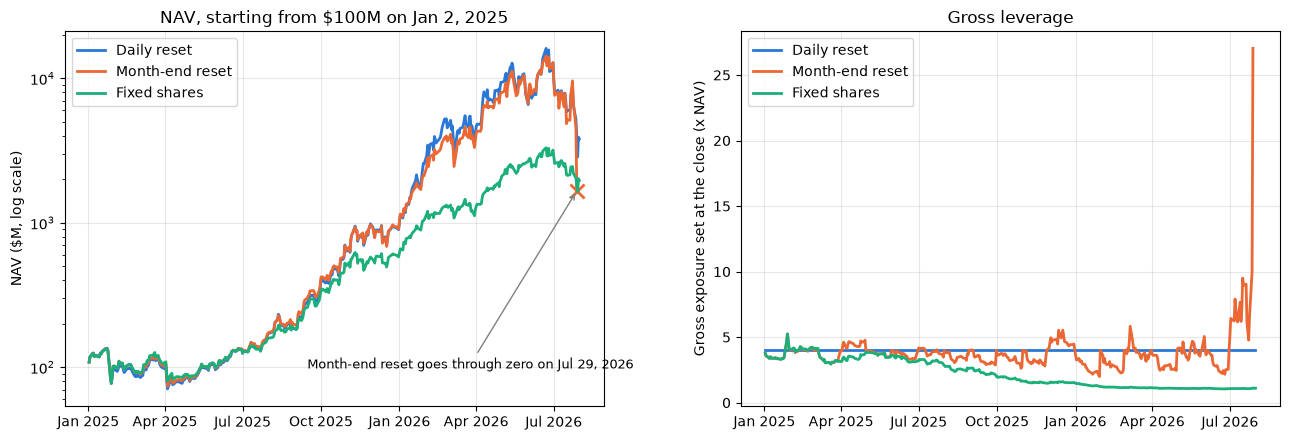

In [12]:
# 2.1
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

NAV0 = 100e6
month_ends = set(returns.index.to_series().groupby(returns.index.to_period("M")).max())

def run_book(rets, rule, nav0=NAV0):
    """Dollar book that starts on the target weights at the prior close. Cash earns nothing.
    rule: 'daily' resets at every close, 'month' at month-end closes, 'fixed' never trades.
    Each row is measured at the close after any reset, so it's the exposure set for the next day."""
    pos = weights * nav0
    cash = nav0 - pos.sum()
    rows = []
    for date, r in rets[tickers].iterrows():
        pos = pos * (1 + r)
        nav = cash + pos.sum()
        if nav <= 0:                       # wiped out: record it and stop
            rows.append({"date": date, "nav": nav})
            break
        turnover = 0.0
        if rule == "daily" or (rule == "month" and date in month_ends):
            target = weights * nav
            turnover = (target - pos).abs().sum() / nav
            pos, cash = target, nav - target.sum()
        rows.append({"date": date, "nav": nav,
                     "long": pos[long_tickers].sum() / nav,
                     "short": pos[short_tickers].sum() / nav,
                     "gross": pos.abs().sum() / nav,
                     "turnover": turnover})
    return pd.DataFrame(rows).set_index("date")

rules = {"Daily reset": "daily", "Month-end reset": "month", "Fixed shares": "fixed"}
paths = {name: run_book(returns.loc["2025-01-02":], rule) for name, rule in rules.items()}

# sanity check: the daily-reset dollar book is exactly the 4x return series
assert np.allclose(paths["Daily reset"]["nav"], NAV0 * (1 + book_4x.loc["2025-01-02":]).cumprod())

colors = {"Daily reset": "#2a78d6", "Month-end reset": "#eb6834", "Fixed shares": "#1baf7a"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, p in paths.items():
    alive = p[p["nav"] > 0]
    axes[0].plot(alive.index, alive["nav"] / 1e6, color=colors[name], lw=2, label=name)
    axes[1].plot(alive.index, alive["gross"], color=colors[name], lw=2, label=name)
    if (p["nav"] <= 0).any():
        axes[0].plot(alive.index[-1], alive["nav"].iloc[-1] / 1e6, "x", color=colors[name], ms=10, mew=2)
        axes[0].annotate(f"{name} goes through zero on {p.index[-1]:%b %d, %Y}",
                         (alive.index[-1], alive["nav"].iloc[-1] / 1e6),
                         xytext=(0.45, 0.1), textcoords="axes fraction", fontsize=9,
                         arrowprops=dict(arrowstyle="->", color="gray"))
axes[0].set_yscale("log")
axes[0].set_ylabel("NAV ($M, log scale)")
axes[0].set_title("NAV, starting from $100M on Jan 2, 2025")
axes[1].set_ylabel("Gross exposure set at the close (x NAV)")
axes[1].set_title("Gross leverage")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
summary_21 = {}
for name, p in paths.items():
    wiped = p.index[p["nav"] <= 0]
    summary_21[name] = {
        "Gross set Jun 22": p.loc["2026-06-22", "gross"],
        "Gross set Jul 23": p.loc["2026-07-23", "gross"],
        "NAV / initial, Jun 22": p.loc["2026-06-22", "nav"] / NAV0,
        "Jul 24-29 return": p.loc["2026-07-29", "nav"] / p.loc["2026-07-23", "nav"] - 1,
        "NAV reaches zero": f"{wiped[0]:%Y-%m-%d}" if len(wiped) else "no",
    }

pd.DataFrame(summary_21).T.style.format({"Gross set Jun 22": "{:.2f}x", "Gross set Jul 23": "{:.2f}x",
                                         "NAV / initial, Jun 22": "{:.1f}x", "Jul 24-29 return": "{:.1%}"})

,Gross set Jun 22,Gross set Jul 23,"NAV / initial, Jun 22",Jul 24-29 return,NAV reaches zero
Daily reset,4.00x,4.00x,161.3x,-66.9%,no
Month-end reset,2.22x,4.77x,142.7x,-110.2%,2026-07-29
Fixed shares,1.05x,1.07x,33.0x,-32.7%,no


In [14]:
# the month-end book through July: reset on June 30, then the gross drifts
month_july = paths["Month-end reset"].loc["2026-06-30":, ["nav", "long", "short", "gross"]].copy()
month_july["nav"] = month_july["nav"] / 1e6
month_july.index = month_july.index.strftime("%Y-%m-%d")
month_july.rename(columns={"nav": "NAV ($M)", "long": "Long (x NAV)", "short": "Short (x NAV)",
                           "gross": "Gross (x NAV)"}).style.format("{:,.2f}", na_rep="-")

,NAV ($M),Long (x NAV),Short (x NAV),Gross (x NAV)
date,,,,
2026-06-30,"12,877.34",2.00,-2.00,4.00
2026-07-01,"9,871.54",2.41,-2.71,5.12
2026-07-02,"7,625.05",2.87,-3.56,6.43
2026-07-06,"8,017.21",2.81,-3.42,6.23
2026-07-07,"6,203.92",3.42,-4.49,7.91
2026-07-08,"6,942.24",3.09,-3.95,7.04
2026-07-09,"7,830.96",2.87,-3.52,6.39
2026-07-10,"8,044.63",2.78,-3.38,6.16
2026-07-13,"6,347.31",3.32,-4.35,7.67


In [15]:
# fixed shares from 2021-01-04: positions set at the Dec 31, 2020 close, same convention as the 2025 start
fixed_21 = run_book(returns.loc["2021-01-04":], "fixed")
d_max, d_min = fixed_21["gross"].idxmax(), fixed_21["nav"].idxmin()

display(pd.Series({
    "Max gross (x NAV)": f"{fixed_21.loc[d_max, 'gross']:.1f}x",
    "Date of max gross": f"{d_max:%Y-%m-%d}",
    "Long / short at max gross (x NAV)": f"{fixed_21.loc[d_max, 'long']:.1f}x / {fixed_21.loc[d_max, 'short']:.1f}x",
    "NAV at max gross ($M)": f"{fixed_21.loc[d_max, 'nav'] / 1e6:.1f}",
    "Min NAV ($M)": f"{fixed_21.loc[d_min, 'nav'] / 1e6:.1f}",
    "Date of min NAV": f"{d_min:%Y-%m-%d}",
    "NAV on Jul 31, 2026 ($M)": f"{fixed_21['nav'].iloc[-1] / 1e6:,.0f}",
}).to_frame("Fixed shares from 2021-01-04"))

# robustness: positions set at the 2021-01-04 close instead (first return on Jan 5)
alt = run_book(returns.loc["2021-01-05":], "fixed")
print(f"If set at the Jan 4 close instead: max gross {alt['gross'].max():.1f}x on {alt['gross'].idxmax():%Y-%m-%d}, "
      f"min NAV ${alt['nav'].min() / 1e6:.1f}M on {alt['nav'].idxmin():%Y-%m-%d}")

,Fixed shares from 2021-01-04
Max gross (x NAV),22.1x
Date of max gross,2021-10-22
Long / short at max gross (x NAV),9.1x / -13.0x
NAV at max gross ($M),20.4
Min NAV ($M),18.5
Date of min NAV,2023-07-19
"NAV on Jul 31, 2026 ($M)","2,306"


If set at the Jan 4 close instead: max gross 28.3x on 2021-10-22, min NAV $14.8M on 2023-07-19


In [16]:
# fixed shares from the July 23, 2026 close, 4x target on $100M, vs the daily-reset book over the same days
fixed_jul = run_book(returns.loc["2026-07-24":"2026-07-29"], "fixed")
daily_jul = NAV0 * (1 + book_4x.loc["2026-07-24":"2026-07-29"]).cumprod()

t21 = pd.DataFrame({
    "Fixed-share NAV ($M)": fixed_jul["nav"] / 1e6,
    "Long (x NAV)": fixed_jul["long"],
    "Short (x NAV)": fixed_jul["short"],
    "Gross (x NAV)": fixed_jul["gross"],
    "Daily-reset NAV ($M)": daily_jul / 1e6,
})
t21.index = t21.index.strftime("%Y-%m-%d")
t21.style.format("{:.2f}")

,Fixed-share NAV ($M),Long (x NAV),Short (x NAV),Gross (x NAV),Daily-reset NAV ($M)
2026-07-24,75.11,2.42,-2.75,5.16,75.11
2026-07-27,55.74,3.13,-3.92,7.06,60.40
2026-07-28,30.06,5.24,-7.56,12.80,43.85
2026-07-29,7.55,18.96,-31.20,50.17,33.09


In [17]:
# what the daily reset has to trade, and what the 2025 fixed-share book actually held going into July 24
daily = paths["Daily reset"]
print(f"Daily reset, average turnover per close: {daily['turnover'].mean():.0%} of NAV")
print("Daily reset, turnover at each reversal close:",
      ", ".join(f"{d:%b %d} {v:.0%}" for d, v in daily.loc["2026-07-24":"2026-07-29", "turnover"].items()))
print(f"Daily reset, gross dollars on Jun 22: ${4 * daily.loc['2026-06-22', 'nav'] / 1e9:.1f}B")

growth = (1 + returns.loc["2025-01-02":"2026-07-23", tickers]).prod()
pos_jul23 = weights * NAV0 * growth
nav_jul23 = NAV0 + pos_jul23.sum()          # cash stays at the initial $100M
(pos_jul23 / nav_jul23).to_frame("Fixed shares from 2025, x NAV at the Jul 23 close").T.round(2)

Daily reset, average turnover per close: 25% of NAV
Daily reset, turnover at each reversal close: Jul 24 116%, Jul 27 103%, Jul 28 134%, Jul 29 116%
Daily reset, gross dollars on Jun 22: $64.5B


ticker,SNDK,MU,VRT,LITE,COHR,BE,ADBE,CRM,ORCL,NOW,WDAY,MDB
"Fixed shares from 2025, x NAV at the Jul 23 close",0.5,0.16,0.04,0.14,0.05,0.13,-0.01,-0.01,-0.01,-0.01,-0.01,-0.02


**Answer 2.1.**

All three books start the same way, with \$100M at 4x set at the December 31, 2024 close, and they end up in completely different places.

Daily reset is the book from Section 1. Gross is 4x at every close, NAV is 161x its starting value on June 22 (\$16.1B), and it loses 66.9% over July 24-29 but never gets close to zero. Month-end reset is almost as high on June 22 (143x), but between resets its gross drifts with the positions. It was reset to 4x on June 30, then the book fell hard in the first half of July and gross climbed to 9.5x by July 16, and it was still at 4.8x going into July 24. The four reversal days cost it 110% of NAV, so it goes through zero on July 29 (NAV of about -\$1B at that close, after gross had hit 27x the night before). Fixed shares never trade, so the winners take over. The longs ran up and the shorts shrank, gross drifted down to 1.05x by June 22, and NAV was 33x its start. It lost only 32.7% in the reversal.

Fixed shares from 2021-01-04 go the other way. The longs fell and the shorts rallied in 2021, so by October 22, 2021 NAV was down to about \$20M and gross was 22.1x (9.1x long and 13.0x short, so the book was net short almost 4x). NAV bottomed at \$18.5M on July 19, 2023, before the longs took off. That's with positions set at the December 31, 2020 close, the same convention as the 2025 start. Setting them at the January 4 close instead gives a 28.3x peak on the same date.

Fixed shares from the July 23, 2026 close start out as exactly the same book as daily reset, so July 24 is the same 24.9% loss for both. After that they split. Daily reset sells back down to 4x after every loss, while fixed shares keep the same dollar positions on a shrinking NAV. Gross goes 5.2x, 7.1x, 12.8x and then 50.2x, and NAV ends at \$7.6M on July 29 vs \$33.1M for daily reset.

Could a fund have actually run these? Month-end reset obviously not, since it goes through zero, and a prime broker would have shut it down well before that at 10x or 27x gross. Fixed shares from 2021 and from July 23 both end up at 20-50x gross on a tiny NAV, which means margin calls and forced selling, not a strategy. Fixed shares from 2025 survive, but by July it's 1.01x long and 0.05x short with half of NAV in SNDK, so it's a concentrated long position and not the 4x market-neutral mandate anymore. Daily reset survives on paper, but only because it trades a lot: about 25% of NAV at every close on average, and 103-134% of NAV at each close during the reversal, selling the longs into the drop and buying back the shorts into their rally. It also means running about \$65B of gross in twelve stocks by June 2026.

So daily resetting assumes a fund that can always trade its whole book at the close for free, in any size, and that just keeps going at 4x no matter what happened the day before. That's a strategy-index convention. It describes a constant-leverage return stream, not what happens to a fund that owns shares. A real fund lives under fixed shares between trades: its leverage is whatever its positions are worth relative to its NAV that day, and losses push leverage up until someone (the risk manager or the prime broker) forces it down.

That's why the same twelve names lose such different fractions of NAV over the reversal. It depends on how much gross each book carried into July 24 (1.07x, 4.0x and 4.8x) and on what happens to that gross during the four days. Daily reset cuts its positions after each loss, so the next loss hits a smaller book. Fixed shares and month-end reset keep their positions, so leverage climbs as NAV falls and each day hurts more than the one before. In a straight four-day sell-off like this one, the daily reset's forced selling is what held the loss to 67% instead of 92%.

---
# 3. One-Day VaR Through the Reversal

## 3.1

> Compute the EWMA volatility forecast of the 4x book from the first day your initialization allows to July 31, 2026, and, for every day in the design window, three one-day 5% VaR forecasts and the CVaR of each: historical simulation, Normal EWMA and filtered historical simulation.
>
> - Plot the EWMA forecast annualized; report the forecast made for July 24, 2026 and the fraction of forecasts for days through June 30, 2026 that were lower.
> - Report the three VaR and CVaR forecasts made at the July 23, 2026 close.
>
> ### VaR Conventions
>
> Historical simulation: minus the 5% quantile of the trailing 252 daily returns; the CVaR is minus the mean of the returns at or below that quantile. Normal EWMA: $\text{VaR}_t = -z_{0.05}\,\sigma_t$ and $\text{CVaR}_t = \sigma_t\,\phi(z_{0.05})/0.05$, with $\sigma_t$ the EWMA forecast. Filtered historical simulation: standardize each past return by the EWMA forecast that applied to it, $z_s = r_s/\sigma_s$; take the 5% quantile and the tail mean of the standardized returns over the trailing 252 days, the same window as the historical simulation; multiply both by the current forecast $\sigma_t$.

In [18]:
# 3.1
from scipy.stats import norm, binomtest     # scipy's stats gets overwritten by the stats() function in 1.1

LAMBDA, Q, WINDOW, INIT_DAYS = 0.94, 0.05, 252, 21
z_q = norm.ppf(Q)

def ewma_vol(r, lam=LAMBDA, init_days=INIT_DAYS):
    """sigma[t] is the forecast for day t, using returns through t-1.
    Seeded with the mean squared return of the first init_days days (zero mean)."""
    x = r.values
    var = np.full(len(x), np.nan)
    var[init_days] = np.mean(x[:init_days] ** 2)
    for t in range(init_days + 1, len(x)):
        var[t] = lam * var[t - 1] + (1 - lam) * x[t - 1] ** 2
    return pd.Series(np.sqrt(var), index=r.index)

def tail(x, q=Q):
    """VaR and CVaR of a sample, as positive losses."""
    cut = np.quantile(x, q)
    return -cut, -x[x <= cut].mean()

sigma = ewma_vol(book_4x)
z_std = book_4x / sigma                     # standardized returns for FHS

fc = pd.DataFrame(index=book_4x.index, dtype=float,
                  columns=["HS VaR", "HS CVaR", "EWMA VaR", "EWMA CVaR", "FHS VaR", "FHS CVaR"])
fc["EWMA VaR"] = -z_q * sigma
fc["EWMA CVaR"] = sigma * norm.pdf(z_q) / Q
r_arr, z_arr = book_4x.values, z_std.values
for t in range(WINDOW, len(r_arr)):
    fc.iloc[t, [0, 1]] = tail(r_arr[t - WINDOW:t])
    past_z = z_arr[t - WINDOW:t]
    if not np.isnan(past_z).any():
        fc.iloc[t, [4, 5]] = np.array(tail(past_z)) * sigma.iloc[t]

for m in ["EWMA", "HS", "FHS"]:
    print(f"First {m} forecast: {fc[f'{m} VaR'].first_valid_index():%Y-%m-%d}")

First EWMA forecast: 2021-02-03
First HS forecast: 2022-01-03
First FHS forecast: 2022-02-02


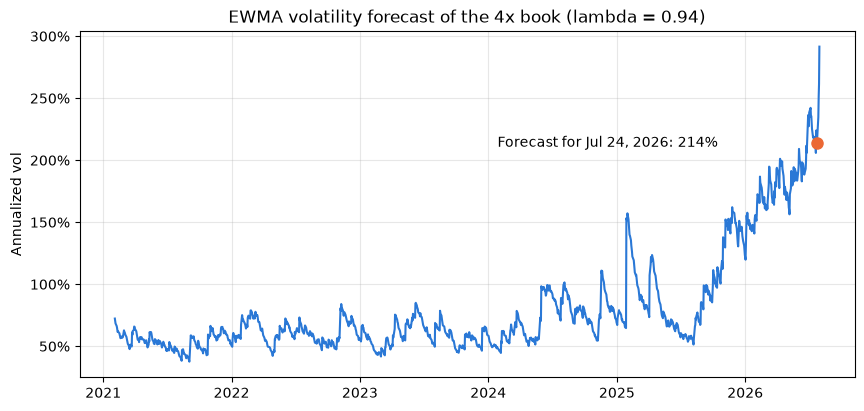

Forecast for Jul 24: 13.48% daily, 213.9% annualized
Share of forecasts for days through Jun 30 that were lower: 99.85% (2 of 1357 were higher: Jun 29, Jun 30)


In [19]:
vol_ann = sigma * np.sqrt(252)
jul24 = pd.Timestamp("2026-07-24")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(vol_ann.index, vol_ann, color="#2a78d6", lw=1.5)
ax.plot(jul24, vol_ann[jul24], "o", color="#eb6834", ms=8)
ax.annotate(f"Forecast for Jul 24, 2026: {vol_ann[jul24]:.0%}", (jul24, vol_ann[jul24]),
            xytext=(-230, 0), textcoords="offset points", va="center")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("Annualized vol")
ax.set_title("EWMA volatility forecast of the 4x book (lambda = 0.94)")
ax.grid(alpha=0.3)
plt.show()

before = vol_ann.loc[:"2026-06-30"].dropna()
print(f"Forecast for Jul 24: {sigma[jul24]:.2%} daily, {vol_ann[jul24]:.1%} annualized")
print(f"Share of forecasts for days through Jun 30 that were lower: {(before < vol_ann[jul24]).mean():.2%} "
      f"({(before >= vol_ann[jul24]).sum()} of {len(before)} were higher: "
      f"{', '.join(f'{d:%b %d}' for d in before[before >= vol_ann[jul24]].index)})")

In [20]:
# the three forecasts made at the July 23 close, for July 24
pd.DataFrame({m: {"VaR": fc.loc[jul24, f"{m} VaR"], "CVaR": fc.loc[jul24, f"{m} CVaR"]}
              for m in ["HS", "EWMA", "FHS"]}).T.style.format("{:.2%}")

,VaR,CVaR
HS,16.56%,20.85%
EWMA,22.17%,27.80%
FHS,21.29%,27.33%


**Answer 3.1.**

We seed $\sigma^2$ with the average squared return of the first 21 trading days, so the first EWMA forecast is for February 3, 2021. With $\lambda = 0.94$ the seed is forgotten within a few months, so it doesn't affect anything after 2021. HS needs 252 past returns and starts on January 3, 2022. FHS needs 252 standardized returns, so it starts a month after that, on February 2, 2022.

In the plot, vol sits around 50-70% annualized for most of 2021-2024. In 2025 it spikes twice (DeepSeek in January and the tariff sell-off in April), comes back down to about 55-70% over the summer, and then climbs almost nonstop: around 150% by the end of 2025 and above 200% by June 2026. The forecast for July 24, 2026 was 13.5% a day, or 214% annualized, and 99.85% of the forecasts for days through June 30 were lower. The only two that were higher were June 29 and 30, when the book had already started falling (it was down 64% from its June 22 peak by July 16). So going into the reversal the model was already saying this was about as risky as the book had ever been.

At the July 23 close, HS gave a VaR of 16.6% and a CVaR of 20.9%, EWMA gave 22.2% and 27.8%, and FHS gave 21.3% and 27.3%. HS is the lowest because its 252-day window still gives full weight to the much calmer months of late 2025, while EWMA and FHS scale to the current vol. Even HS was saying that one day in twenty should cost at least a sixth of NAV.

## 3.2

> Backtest the three methods over 2025-01-02 to 2026-07-23 and over 2021-01-04 to 2024-12-31. For each method and window report
>
> - the number of forecasts, the number of breaches and the hit ratio
> - the longest run of consecutive breaches
> - the mean realized loss on breach days beside the mean CVaR forecast on those days
>
> A method whose window has not yet filled starts later; report its count and say so. Which methods are calibrated in each window, and where the hit ratio is near 5%, does the breach-day loss match the CVaR forecast?

In [21]:
# 3.2
def longest_run(flags):
    best = run = 0
    for f in flags:
        run = run + 1 if f else 0
        best = max(best, run)
    return best

def backtest(start, end):
    rows = {}
    for m in ["HS", "EWMA", "FHS"]:
        var = fc.loc[start:end, f"{m} VaR"].dropna()
        cvar = fc.loc[var.index, f"{m} CVaR"]
        loss = -book_4x.loc[var.index]
        hit = loss > var
        rows[m] = {
            "First forecast": f"{var.index[0]:%Y-%m-%d}",
            "Forecasts": len(var),
            "Breaches": int(hit.sum()),
            "Hit ratio": hit.mean(),
            "Binomial p-value": binomtest(int(hit.sum()), len(var), Q).pvalue,
            "Longest run": longest_run(hit),
            "Mean loss on breach days": loss[hit].mean(),
            "Mean CVaR on breach days": cvar[hit].mean(),
        }
    return pd.DataFrame(rows).T

fmt_32 = {"Hit ratio": "{:.1%}", "Binomial p-value": "{:.3f}",
          "Mean loss on breach days": "{:.2%}", "Mean CVaR on breach days": "{:.2%}"}
for label, (a, b) in {"2025-01-02 to 2026-07-23": ("2025-01-02", "2026-07-23"),
                      "2021-01-04 to 2024-12-31": ("2021-01-04", "2024-12-31")}.items():
    display(backtest(a, b).style.format(fmt_32).set_caption(label))

,First forecast,Forecasts,Breaches,Hit ratio,Binomial p-value,Longest run,Mean loss on breach days,Mean CVaR on breach days
HS,2025-01-02,389,38,9.8%,0.000,2,15.40%,14.43%
EWMA,2025-01-02,389,15,3.9%,0.352,2,19.99%,17.80%
FHS,2025-01-02,389,23,5.9%,0.414,2,17.51%,18.53%


,First forecast,Forecasts,Breaches,Hit ratio,Binomial p-value,Longest run,Mean loss on breach days,Mean CVaR on breach days
HS,2022-01-03,753,44,5.8%,0.277,2,8.30%,7.96%
EWMA,2021-02-03,984,43,4.4%,0.421,2,8.32%,7.60%
FHS,2022-02-02,732,36,4.9%,1.000,2,8.31%,8.48%


**Answer 3.2.**

In 2021-2024 all three methods are calibrated. The hit ratios are 5.8% for HS, 4.4% for EWMA and 4.9% for FHS. None of them is far from 5% on a binomial test (p-values of 0.28, 0.42 and 1.00), and none had more than two breaches in a row. HS and FHS start later because their windows need a year of data first, so they have 753 and 732 forecasts against 984 for EWMA.

In 2025-2026 HS fails. It was breached on 38 of 389 days (9.8%, p < 0.001), because a flat 252-day window kept lagging behind a volatility level that kept going up. EWMA (3.9%) and FHS (5.9%) are both fine. Neither window includes the reversal itself, since this backtest stops on July 23.

Where the hit ratio is close to 5%, the next question is whether the losses on breach days look like the CVaR. FHS gets this right: in 2025-26 its average breach-day loss was 17.5% against an average CVaR of 18.5%, and in 2021-24 it was 8.3% against 8.5%. EWMA doesn't. Its breach-day losses averaged 20.0% against a CVaR of 17.8% in 2025-26, and 8.3% against 7.6% before that. So EWMA gets the number of bad days right but understates how bad they are, which is what the normal's thin tails would do. HS in 2021-24 is in between (8.3% against 8.0%). FHS is the only method that gets both the frequency and the size right in both windows.

## 3.3

> For each of the four reversal days, July 24, 27, 28 and 29, report the realized loss of the 4x book as a multiple of the VaR each method had forecast for that day, and the four-day loss as a multiple of $\sqrt{4}$ times each method's July 23 forecast.
>
> Over 2025-01-02 to 2026-07-31, compare overlapping 4-day returns of the 4x book with $\sqrt{4}$ times the Normal EWMA one-day VaR in force at the start of each window. Report:
>
> - The hit ratio.
> - The largest ratio of realized loss to scaled VaR, with its date.
>
> For each method, count the reversal-day breaches. Does the four-day loss challenge $\sqrt{h}$ scaling? Say which of its assumptions (independent daily returns, constant volatility, a zero mean) could account for the gap between the scaled forecast and the realized loss, and what one four-day realization can and cannot establish about them. Is the largest one-day ratio on a reversal day?

In [22]:
# 3.3
methods = ["HS", "EWMA", "FHS"]
rev_days = pd.to_datetime(["2026-07-24", "2026-07-27", "2026-07-28", "2026-07-29"])
rev_loss = -book_4x.loc[rev_days]
four_day_loss = 1 - (1 + book_4x.loc[rev_days]).prod()
print("Daily losses:", ", ".join(f"{d:%b %d} {v:.1%}" for d, v in rev_loss.items()), f"| four-day loss: {four_day_loss:.1%}")

t33 = pd.DataFrame({m: rev_loss / fc.loc[rev_days, f"{m} VaR"] for m in methods})
t33.index = t33.index.strftime("%b %d")
breaches = (t33 > 1).sum()
t33.loc["4-day loss / (sqrt(4) x Jul 23 VaR)"] = [four_day_loss / (2 * fc.loc[jul24, f"{m} VaR"]) for m in methods]
t33.loc["Reversal-day breaches"] = breaches
t33.round(2)

Daily losses: Jul 24 24.9%, Jul 27 19.6%, Jul 28 27.4%, Jul 29 24.5% | four-day loss: 66.9%


,HS,EWMA,FHS
Jul 24,1.50,1.12,1.17
Jul 27,1.12,0.83,0.84
Jul 28,1.53,1.13,1.15
Jul 29,1.34,0.94,0.92
4-day loss / (sqrt(4) x Jul 23 VaR),2.02,1.51,1.57
Reversal-day breaches,4.00,2.00,2.00


In [23]:
# overlapping 4-day windows over the report window vs sqrt(4) x the EWMA VaR in force at the start of each
r_rep = book_4x.loc["2025-01-02":"2026-07-31"]
four_day = (1 + r_rep).rolling(4).apply(np.prod, raw=True).shift(-3).dropna() - 1   # indexed by the window's first day
scaled_var = 2 * fc.loc[four_day.index, "EWMA VaR"]
ratio_4d = -four_day / scaled_var

print(f"Windows: {len(ratio_4d)} (first starts {ratio_4d.index[0]:%Y-%m-%d}, last starts {ratio_4d.index[-1]:%Y-%m-%d})")
print(f"Hit ratio: {(ratio_4d > 1).mean():.1%} ({(ratio_4d > 1).sum()} windows)")
print(f"Largest ratio: {ratio_4d.max():.2f}, window starting {ratio_4d.idxmax():%Y-%m-%d}")
print(f"Window starting Jul 24, 2026: {ratio_4d[jul24]:.2f}")

one_day = pd.DataFrame({m: -r_rep / fc.loc[r_rep.index, f"{m} VaR"] for m in methods})
pd.DataFrame({"Largest one-day ratio": one_day.max().round(2),
              "Date": one_day.idxmax().dt.strftime("%Y-%m-%d"),
              "Largest on a reversal day": one_day.loc[rev_days].max().round(2)})

Windows: 392 (first starts 2025-01-02, last starts 2026-07-28)
Hit ratio: 3.3% (13 windows)
Largest ratio: 3.05, window starting 2025-01-23
Window starting Jul 24, 2026: 1.51


,Largest one-day ratio,Date,Largest on a reversal day
HS,5.23,2025-01-27,1.53
EWMA,5.37,2025-01-27,1.13
FHS,6.65,2025-01-27,1.17


In [24]:
# checking the sqrt(h) assumptions on the report window
four_day_all = (1 + r_rep).rolling(4).apply(np.prod, raw=True).dropna() - 1
print(f"Lag-1 autocorrelation of daily returns: {r_rep.autocorr():.3f}")
print(f"Var(4-day return) / (4 x var(1-day return)): {four_day_all.var() / (4 * r_rep.var()):.2f}")
print("EWMA forecast for each reversal day (daily):", ", ".join(f"{d:%b %d} {v:.1%}" for d, v in sigma[rev_days].items()))
print(f"4-day 5% VaR using those four forecasts: {-z_q * np.sqrt((sigma[rev_days] ** 2).sum()):.1%} "
      f"vs sqrt(4) x Jul 23 EWMA VaR: {2 * fc.loc[jul24, 'EWMA VaR']:.1%}")
print(f"Average daily return, Jan 2, 2025 to Jul 23, 2026: {book_4x.loc['2025-01-02':'2026-07-23'].mean():+.2%}")

Lag-1 autocorrelation of daily returns: -0.005
Var(4-day return) / (4 x var(1-day return)): 0.93
EWMA forecast for each reversal day (daily): Jul 24 13.5%, Jul 27 14.4%, Jul 28 14.8%, Jul 29 15.8%
4-day 5% VaR using those four forecasts: 48.2% vs sqrt(4) x Jul 23 EWMA VaR: 44.3%
Average daily return, Jan 2, 2025 to Jul 23, 2026: +1.55%


**Answer 3.3.**

Day by day, the reversal wasn't a big miss. Each day's loss was between 0.8x and 1.5x the VaR forecast for it. HS was breached on all four days, and EWMA and FHS on two each (July 24 and 28). The largest one-day ratio in the report window isn't in July 2026 at all. It's January 27, 2025 (DeepSeek), when the book lost 36% on a day the EWMA VaR was 6.7%, a ratio of 5.4x (6.7x for FHS). The biggest ratio on a reversal day is only 1.5x.

Over four days it looks worse. The 66.9% four-day loss is 2.0x $\sqrt{4}$ times the HS VaR made on July 23, and about 1.5x for EWMA and FHS. But across all 392 overlapping four-day windows in the report window, the loss beat $\sqrt{4}$ times the EWMA VaR only 3.3% of the time, and the worst ratio (3.05) was again the DeepSeek window starting January 23, 2025, not the reversal (1.51). So $\sqrt{h}$ scaling wasn't too low on average here. The reversal challenges it, but one window isn't enough to break it.

On the three assumptions, independence is the most likely culprit. Four losses in a row in the same direction is what an unwind looks like, and that kind of short-run momentum makes the four-day variance bigger than four times the one-day variance. Over the report window as a whole there's no sign of it, though: the daily autocorrelation is basically zero (-0.005) and the four-day variance is 0.93 times four times the daily variance. Constant volatility explains some of the gap. The EWMA forecast went from 13.5% to 15.8% a day during the four days, and using those forecasts gives a four-day 5% VaR of about 48% instead of 44%. That still leaves a lot unexplained. Zero mean actually works the other way. Before the reversal the book's average day was +1.55%, so assuming a zero mean made the forecast more pessimistic, not less. The mean only helps explain the loss if it suddenly turned very negative, which is really just another way of describing the unwind.

What one four-day loss can show is that $\sqrt{4}$ times a one-day VaR can be badly wrong in a single crowded exit. What it can't do is tell the three explanations apart, or prove the scaling is biased. Under the normal at the July 23 vol it's roughly a 1-in-150 event (see 3.4), and with about 100 non-overlapping four-day windows in the report window, seeing one of those isn't that surprising.

## 3.4

> Using the July 23 EWMA volatility scaled by $\sqrt{4}$ and a zero mean, compute the probability under the normal of a four-day loss at least as large as the one realized. Compute it again by drawing four standardized returns at random from the 252-day FHS window, re-inflating them by the July 23 volatility, and compounding. Then recompute the FHS VaR and CVaR forecasts made at the July 23 close, and this probability, with a 504-day standardization window.
>
> - Report the probabilities, and the 504-day VaR and CVaR beside the 252-day ones.
> - Report the worst standardized return in each window, its date, and whether one draw of it reaches the realized loss.
>
> Say what that one observation does to the estimate, how far the conclusion depends on keeping it, and what each probability is a statement about: the model, the volatility level, or the book.

In [25]:
# 3.4
N_DRAWS, SEED = 1_000_000, 36700
rng = np.random.default_rng(SEED)
sig_jul23 = sigma[jul24]                  # the forecast made at the July 23 close
pos24 = book_4x.index.get_loc(jul24)

p_normal = norm.cdf(-four_day_loss / (np.sqrt(4) * sig_jul23))

def sim_prob(z):
    """Draw 4 standardized returns, re-inflate by the Jul 23 vol, compound. A day below -100% wipes the book out."""
    draws = np.maximum(rng.choice(z, size=(N_DRAWS, 4)) * sig_jul23, -1.0)
    return (1 - (1 + draws).prod(axis=1) >= four_day_loss).mean()

def exact_prob(z):
    """Same probability, counted over every possible set of 4 draws (pairs of pairs, in logs)."""
    g = 1 + sig_jul23 * z
    logs = np.where(g > 0, np.log(np.where(g > 0, g, 1.0)), -np.inf)
    pairs = np.sort(np.add.outer(logs, logs).ravel())
    cutoff = np.log(1 - four_day_loss)
    return np.searchsorted(pairs, cutoff - pairs, side="right").sum() / len(z) ** 4

def fhs_check(window, drop=None):
    z = z_std.iloc[pos24 - window:pos24]          # the window behind the Jul 23 forecast
    if drop is not None:
        z = z.drop(pd.Timestamp(drop))
    var, cvar = tail(z.values)
    return {
        "Window": f"{z.index[0]:%Y-%m-%d} to {z.index[-1]:%Y-%m-%d}",
        "FHS VaR": var * sig_jul23,
        "FHS CVaR": cvar * sig_jul23,
        "P(4-day loss >= realized), simulated": sim_prob(z.values),
        "P(4-day loss >= realized), exact": exact_prob(z.values),
        "Worst z": z.min(),
        "Date of worst z": f"{z.idxmin():%Y-%m-%d}",
        "Loss from one draw of worst z": -z.min() * sig_jul23,
        "One draw reaches the realized loss": -z.min() * sig_jul23 >= four_day_loss,
    }

print(f"Four-day loss: {four_day_loss:.1%}, Jul 23 EWMA vol: {sig_jul23:.2%} daily")
print(f"Normal, zero mean, sqrt(4) x Jul 23 vol: P = {p_normal:.2%} (a {four_day_loss / (2 * sig_jul23):.2f}-sigma loss)")
print(f"Same calculation at the median EWMA vol through Jun 30 ({sigma.loc[:'2026-06-30'].median() * np.sqrt(252):.0%} annualized): "
      f"P = {norm.cdf(-four_day_loss / (2 * sigma.loc[:'2026-06-30'].median())):.0e}")
print(f"FHS bootstrap: {N_DRAWS:,} sets of 4 draws per window, seed {SEED}")

t34 = pd.DataFrame({"252-day window": fhs_check(252),
                    "504-day window": fhs_check(504),
                    "504-day, without 2025-01-27": fhs_check(504, drop="2025-01-27")})
pct_rows = ["FHS VaR", "FHS CVaR", "Loss from one draw of worst z"]
prob_rows = ["P(4-day loss >= realized), simulated", "P(4-day loss >= realized), exact"]
t34.style.format("{:.2%}", subset=(pct_rows, t34.columns)) \
         .format("{:.3%}", subset=(prob_rows, t34.columns)) \
         .format("{:.2f}", subset=(["Worst z"], t34.columns))

Four-day loss: 66.9%, Jul 23 EWMA vol: 13.48% daily
Normal, zero mean, sqrt(4) x Jul 23 vol: P = 0.65% (a 2.48-sigma loss)
Same calculation at the median EWMA vol through Jun 30 (64% annualized): P = 5e-17
FHS bootstrap: 1,000,000 sets of 4 draws per window, seed 36700


,252-day window,504-day window,"504-day, without 2025-01-27"
Window,2025-07-23 to 2026-07-23,2024-07-19 to 2026-07-23,2024-07-19 to 2026-07-23
FHS VaR,21.29%,20.49%,20.43%
FHS CVaR,27.33%,31.62%,27.83%
"P(4-day loss >= realized), simulated",0.021%,0.908%,0.138%
"P(4-day loss >= realized), exact",0.021%,0.926%,0.136%
Worst z,-3.20,-8.83,-4.45
Date of worst z,2025-08-27,2025-01-27,2025-04-03
Loss from one draw of worst z,43.07%,118.95%,59.97%
One draw reaches the realized loss,False,True,False


In [26]:
# how much of the 504-day probability is that one day, and how big were the reversal shocks themselves
print(f"P(at least one of the 4 draws is Jan 27, 2025) in the 504-day window: {1 - (1 - 1 / 504) ** 4:.2%}")
print("Standardized returns on the reversal days:", ", ".join(f"{d:%b %d} {v:.2f}" for d, v in z_std[rev_days].items()))

P(at least one of the 4 draws is Jan 27, 2025) in the 504-day window: 0.79%
Standardized returns on the reversal days: Jul 24 -1.85, Jul 27 -1.36, Jul 28 -1.85, Jul 29 -1.55


**Answer 3.4.**

Under the normal with a zero mean and $\sqrt{4}$ times the July 23 vol, a 66.9% four-day loss is a 2.48-sigma event, so the probability is 0.65%, about 1 in 150. Bootstrapping from the 252-day FHS window gives a much smaller number: 0.021% simulated (1,000,000 sets of four draws, seed 36700), and 0.021% when every possible combination is counted exactly. The worst standardized return in that window is -3.20 on August 27, 2025. One draw of it costs 43%, which doesn't reach the realized loss, so you need several bad draws together to get there.

With a 504-day window the FHS VaR barely moves (20.5% vs 21.3%), but the CVaR jumps from 27.3% to 31.6% and the probability goes up about 45-fold, to 0.93% (0.91% simulated). That's almost all one day. The longer window now includes January 27, 2025, with a standardized return of -8.83, and one draw of it is a 119% loss, which wipes out the book on its own. The chance that at least one of the four draws lands on that day is 0.79%, so it accounts for about 85% of the 0.93%. Taking just that day out drops the probability to 0.14% and the CVaR back to 27.8%.

So the FHS answer depends heavily on one observation. Depending on choices that are basically arbitrary (252 vs 504 days, keep January 27 or not), the estimate goes from 0.02% to 0.9%, so we can't really pin down how rare this was. The conclusion that the reversal was a rare tail event is only as strong as whatever you decide to do with that one day.

The three probabilities are about different things. All of them use the same July 23 vol, and that's what makes a 67% four-day loss possible at all: at the median vol level of the book's history (64% annualized), the normal probability of the same loss is basically zero (around 5e-17). The normal number is then a statement about the model, i.e. what independent normal shocks would do at that vol level. The FHS numbers keep the vol level but swap in the book's own past shocks, so they're statements about the book's recent history, and the 504-day one is mostly a statement about January 27, 2025. It's also worth noticing that none of the four reversal days was extreme on its own, with standardized returns of only -1.4 to -1.9. The loss came from the volatility level plus four moderate shocks in a row, which none of these iid models treats as likely.

---
# 4. Where the Risk Sat

Section 4 uses daily excess returns and two estimation windows: 2021-01-04 to 2024-12-31 and 2025-01-02 to 2026-06-30. The 1x book keeps the betas readable; multiply by four for the 4x book.

## 4.1

> Regress each of the twelve names, the long sleeve (+50% of NAV at 1x), the short sleeve (-50%) and the 1x book on two factor sets: `SPY` alone and `SPY` with `SMH`.
>
> Report alpha, factor loadings, $R^2$ and residual volatility for the book and the two sleeves, annualized where appropriate. Use the individual-name regressions to verify the book's exposure vector $B\boldsymbol{w}$; a full table of individual regressions is not required.
>
> The book has zero net exposure. What is its market beta in each window, and which sleeve betas produce it? Did the short sleeve hedge the long sleeve's largest exposure, add to it, or leave it alone?
>
> ### Portfolio Exposures
>
> Regress each name's excess return on the factor excess returns, $\tilde r_{i,t} = \alpha_i + \boldsymbol{\beta}_i' \tilde{\boldsymbol{f}}_t + \epsilon_{i,t}$, and stack the loadings in $B$, one column per name. The book with weights $\boldsymbol{w}$ has factor exposure $B\boldsymbol{w}$ and residual return $\boldsymbol{w}'\boldsymbol{\epsilon}_t$.

In [44]:
#4.1

**Answer 4.1.**

## 4.2

> Estimate the 1x book's beta to `SPY` alone, and to `SPY` and `SMH` together, on a trailing one-year window at each quarter-end from September 2021 to June 2026. Tabulate or plot. The weights never changed. Did the exposures?

In [45]:
#4.2

**Answer 4.2.**

## 4.3

> For each factor set in 4.1 and each window, report the average pairwise correlation of the residuals among the long names, among the short names, and across the sleeves, next to the same averages for the raw returns. Then, for the 2025-01-02 to 2026-06-30 window, compute the 1x book's variance three ways: from the sample covariance of the twelve names; from the factor model with a diagonal residual covariance; from the factor model with the full residual covariance. Do this for `SPY` alone and for `SPY` plus `SMH`.
>
> - Convert each variance to a 4x one-day Normal 5% VaR.
>
> After the factors are removed, how many dimensions of risk are left in this book? Which term does the diagonal drop, and how large is it as a share of the book's variance?
>
> ### Variance Decomposition
>
> $\sigma^2_{\text{book}} = (B\boldsymbol{w})'\,\Sigma_f\,(B\boldsymbol{w}) + \boldsymbol{w}'\,\Sigma_\epsilon\,\boldsymbol{w}$. A factor risk model usually replaces $\Sigma_\epsilon$ with its diagonal; the sample covariance of the twelve names needs no such assumption.

In [46]:
#4.3

**Answer 4.3.**

## 4.4

> Attribute the July 24 to 29 loss of the 4x book to its factor exposure and its residual, as sums of daily contributions, using betas from each window and both factor sets from 4.1.
>
> - Report the systematic share under each of the four combinations.
>
> Was the reversal a factor event or a residual event, and does the answer depend on what you call a factor?

In [47]:
#4.4

**Answer 4.4.**

---
# 5. Horizon and Survival

## 5.1

> Compute daily log excess returns of the 1x and 4x books. For 2021-01-04 to 2024-12-31, 2025-01-02 to 2026-06-30 and 2021-01-04 to 2026-06-30, report
>
> - the annualized arithmetic mean, the annualized log mean, the annualized volatility, and the gap between the two means
> - for leverage 1x, 2x, 3x and 4x, the probability of underperforming cash over one month, one year and five years with the Barnstable formula, $\Pr\big[\texttt{r}_{t,t+h} < \texttt{r}^f_{t,t+h}\big] = \Phi\!\left(-\sqrt{h}\,\mu/\sigma\right)$, with $\mu$ and $\sigma$ the daily mean and standard deviation of the log excess return over cash
> - a plot of the probability against horizon for the four leverage levels on the 2021 to 2024 parameters
>
> What sign does the 4x log mean take in each window, and what produces the gap? At each leverage, does a longer horizon raise or lower the probability? State in one sentence how this relates to the argument Barnstable's trustees made about stocks.
>
> ### Log Returns
>
> Write $\texttt{r}_t = \ln(1+r_t)$ for the log return.

In [48]:
#5.1

**Answer 5.1.**

## 5.2

> Simulate the probability that the 4x book suffers a maximum drawdown of at least 50% within one year and within five years, using the 2021-01-04 to 2026-06-30 parameters: once from a normal with the book's daily log mean and standard deviation, once by resampling the book's own daily returns. State the number of paths and random seed.
>
> Compare the probabilities. Does the shape of the return distribution or the level of its volatility drive the answer? Explain how a drawdown from a running peak differs from a loss relative to initial wealth.
>
> For each simulated path, cumulate log returns from initial wealth of one, track the running maximum including that initial value, and record the largest drawdown.

In [49]:
#5.1

**Answer 5.2.**

## 5.3

> As of June 30, 2026, what gross exposure would you have recommended for this mandate, on what criterion, and estimated on which window? Give the number and the reasoning.

In [50]:
#5.3

**Answer 5.3.**

---
# 6. The Risk-Managed Mandate

The managed book keeps the twelve names, stays long the long sleeve and short the short sleeve, and never exceeds 4x gross. Every control uses only information available at the close before it acts. Every control is a rebalancing rule, and the constant-leverage comparators in 6.2 are daily-reset books at lower gross, so the comparison isolates timing from level.

## 6.1

> Before computing any Section 6 result, and before using any return after July 31, 2026, write a dated markdown cell that states
>
> - two numeric pass-fail criteria, one about risk and one about return or the cost of control
> - the control or controls you will test, chosen from a volatility target, a VaR or CVaR limit, a drawdown rule, a factor hedge, a sleeve or position cap, or a combination
> - every parameter
>
> One well-motivated control is sufficient. You may use the risk measure or hedge developed in Section 7 as part of it; those questions still require their own analysis. Keep the original declaration. Record any revision in a second dated cell.

In [51]:
#6.1

**Answer 6.1.**

## 6.2

> Implement the declared controls on the design window. Over the report window, 2025-01-02 to 2026-07-31, for the managed book, the unmanaged 4x book, the 1x book, and a constant-leverage comparator whose gross exposure equals the managed book's average gross over the report window, report
>
> - gross exposure through time and the dates on which the controls bound
> - cumulative return to July 23, the July 24 to 29 return, and cumulative return to July 31
> - annualized volatility, Sharpe ratio and maximum drawdown
> - average gross exposure, and the gross exposure set at the July 23 close (for July 24)
>
> Compare each control with constant exposure at the same average gross leverage to distinguish timing from position size. State what each control cost or earned before the reversal and during it, against the unmanaged book and against its comparator, and whether an investor reviewing the managed book in April 2026 would have kept it.

In [52]:
#6.2

**Answer 6.2.**

## 6.3

> Run the same controls, unchanged, from August 3, 2026 to the end of the file, with the same comparators.
>
> - Report the same statistics plus the worst day.
> - Apply the criteria declared in 6.1: pass or fail, by your own test.
>
> If the design window and the holdout disagree about a control, say which you believe and why.

In [53]:
#6.3

**Answer 6.3.**